In [ ]:
import pandas as pd

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Best parameters: {'learning_rate': 0.05, 'max_depth': 4, 'max_features': 'log2', 'n_estimators': 300, 'subsample': 0.8}
Train -> R²: 0.872, RMSE: 0.187, MAE: 0.134
Validation -> R²: 0.779, RMSE: 0.236, MAE: 0.175
Test -> R²: 0.790, RMSE: 0.236, MAE: 0.175


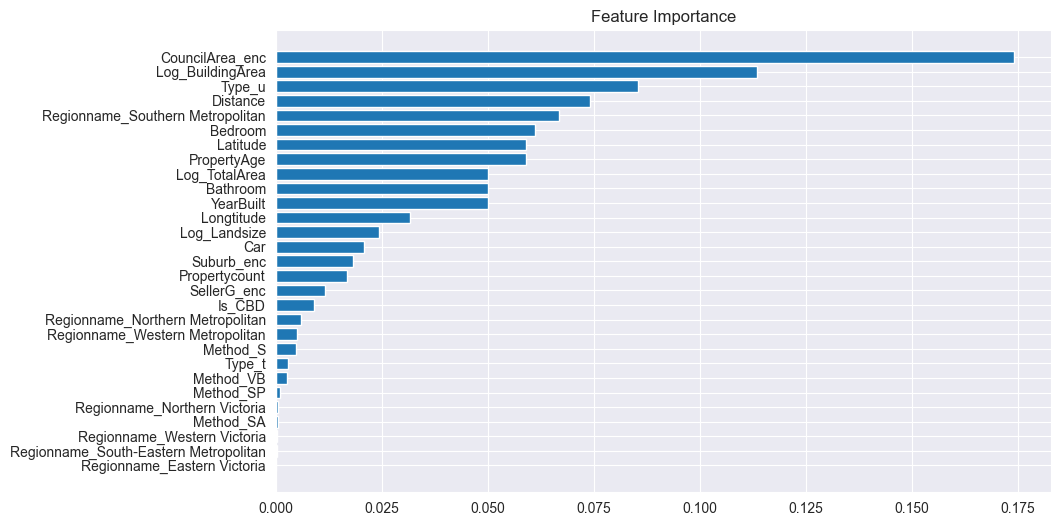

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import matplotlib.pyplot as plt

# 1. Load data
df = pd.read_csv("data/melbourne_housing_cleaned_v2.csv")

# 2. Define features and target
# Replace 'target_column' with your actual target column name
X = df.drop(columns=['Log_Price','Log_Price_Per_SqM'])
y = df["Log_Price"]

# 3. Split data: 60% train, 20% validation, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'max_features': ['sqrt', 'log2', None]
}

# 5. Grid Search
grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print("Best parameters:", grid.best_params_)

# 4. Train default GradientBoostingRegressor
#model = GradientBoostingRegressor(random_state=42)
#model.fit(X_train, y_train)

# 5. Evaluation function
def evaluate(model, X, y, dataset_name="Dataset"):
    y_pred = model.predict(X)
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    mae = mean_absolute_error(y, y_pred)
    print(f"{dataset_name} -> R²: {r2:.3f}, RMSE: {rmse:.3f}, MAE: {mae:.3f}")

# 6. Evaluate on all datasets
evaluate(best_model, X_train, y_train, "Train")
evaluate(best_model, X_val, y_val, "Validation")
evaluate(best_model, X_test, y_test, "Test")

importances = best_model.feature_importances_
sorted_idx = importances.argsort()
plt.figure(figsize=(10,6))
plt.barh(range(len(sorted_idx)), importances[sorted_idx])
plt.yticks(range(len(sorted_idx)), [X.columns[i] for i in sorted_idx])
plt.title("Feature Importance")
plt.show()

After evaluating our model on the full dataset and using grid search to tune our model parameters we will use the feature importances detected and the best parameters detected

Train -> R²: 0.898, RMSE: 0.167, MAE: 0.116
Validation -> R²: 0.776, RMSE: 0.238, MAE: 0.177
Test -> R²: 0.776, RMSE: 0.243, MAE: 0.180


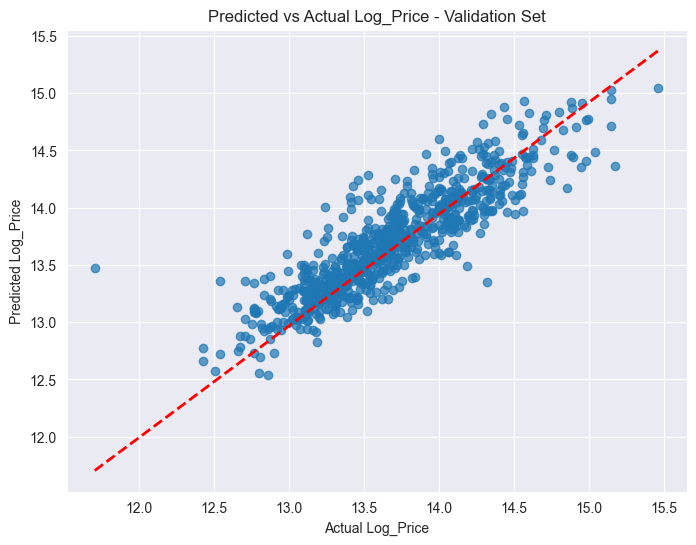

In [14]:
# Use only the feature-important columns
final_features = [
    'Distance',
    'Bedroom',
    'Bathroom',
    'CouncilArea_enc',
    'Type_u',
    'Regionname_Southern Metropolitan',
    'Log_TotalArea',
    'Log_BuildingArea',
    'PropertyAge',
    'YearBuilt',
    'Latitude',
    'Longtitude',
]


X = df[final_features]
y = df["Log_Price"]

# Split data
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

# 4. Train Gradient Boosting with best parameters
best_model = GradientBoostingRegressor(
    learning_rate=0.05,
    max_depth=5,
    max_features='sqrt',
    n_estimators=300,
    subsample=1.0,
    random_state=42
)
best_model.fit(X_train, y_train)

# 5. Make predictions
y_train_pred = best_model.predict(X_train)
y_val_pred = best_model.predict(X_val)
y_test_pred = best_model.predict(X_test)

# 6. Evaluation function
def evaluate(y_true, y_pred, dataset_name="Dataset"):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{dataset_name} -> R²: {r2:.3f}, RMSE: {rmse:.3f}, MAE: {mae:.3f}")

# Evaluate on all sets
evaluate(y_train, y_train_pred, "Train")
evaluate(y_val, y_val_pred, "Validation")
evaluate(y_test, y_test_pred, "Test")

# 7. Graph: Predicted vs Actual (Validation set)
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_test_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_val.max()], 'r--', lw=2)
plt.xlabel("Actual Log_Price")
plt.ylabel("Predicted Log_Price")
plt.title("Predicted vs Actual Log_Price - Validation Set")
plt.show()

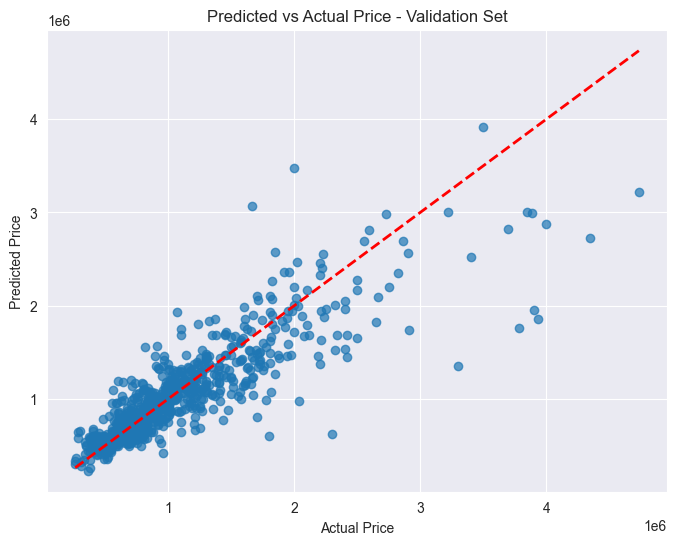

In [13]:
# Optional: Convert Log_Price back to original scale for graph
plt.figure(figsize=(8,6))
plt.scatter(np.exp(y_val), np.exp(y_val_pred), alpha=0.7)
plt.plot([np.exp(y_val).min(), np.exp(y_val).max()],
         [np.exp(y_val).min(), np.exp(y_val).max()], 'r--', lw=2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predicted vs Actual Price - Validation Set")
plt.show()